# 02 – Vérification du MNT à 10 m et des glaciers d'étude

Contrôles de `data/processed/mnt_10m.tif` (produit par `src/prepare_dem.py`) et de `data/processed/sgi2023_zone.gpkg` (produit par `src/prepare_sgi.py`) :

1. vue d'ensemble : emprise, couverture, glaciers retenus ;
2. raccords entre dalles : pas de marche tous les kilomètres ;
3. comparaison avec le MNT 2 m d'origine sur l'Alphubel ;
4. altitudes des sommets et des forages glenglat.

In [1]:
import sys
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from matplotlib.patches import Rectangle
from pyproj import Transformer
from rasterio.windows import from_bounds

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from config import EMPRISE, PROCESSED, RAW, RES_MNT
from relief import ombrage

BLEU, ORANGE, ENCRE = "#2a78d6", "#eb6834", "#1a1a1a"
FIG = ROOT / "figures"

In [2]:
with rasterio.open(PROCESSED / f"mnt_{RES_MNT}m.tif") as src:
    mnt, transform, crs = src.read(1), src.transform, src.crs
glaciers = gpd.read_file(PROCESSED / "sgi2023_zone.gpkg")
ombre = ombrage(mnt, RES_MNT)
xmin, ymin, xmax, ymax = EMPRISE
etendue = (xmin, xmax, ymin, ymax)  # ordre attendu par imshow

print("CRS :", crs, "| pixel :", RES_MNT, "m | taille :", mnt.shape[1], "x", mnt.shape[0])
print(f"Couverture : {np.isfinite(mnt).mean():.1%} | altitudes : {np.nanmin(mnt):.0f}–{np.nanmax(mnt):.0f} m")
print("Glaciers retenus :", len(glaciers), f"({glaciers['area_km2'].sum():.1f} km²)")

CRS : EPSG:2056 | pixel : 10 m | taille : 3400 x 2300
Couverture : 97.1% | altitudes : 1121–4543 m
Glaciers retenus : 127 (158.6 km²)


## 1. Vue d'ensemble

On attend un rectangle plein (sauf deux petits coins au sud, hors de Suisse), et aucun glacier retenu coupé par le bord. Les cadres numérotés sont les zooms de la partie 2.

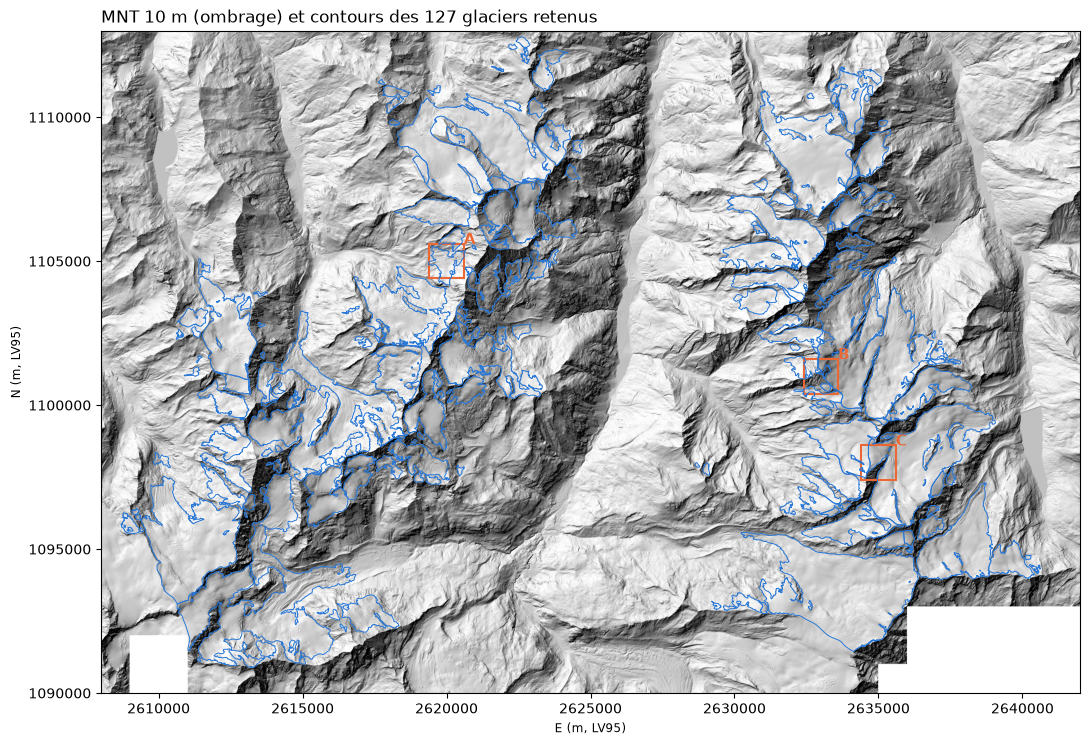

In [3]:
# Trois croisements de dalles (coins de kilomètres ronds) en terrain raide, pour la partie 2
croisements = {"A": (2_620_000, 1_105_000), "B": (2_633_000, 1_101_000), "C": (2_635_000, 1_098_000)}
DEMI = 600  # demi-côté des zooms (m)

fig, ax = plt.subplots(figsize=(11, 8))
ax.imshow(ombre, cmap="gray", extent=etendue, vmin=-0.2, vmax=1)
glaciers.boundary.plot(ax=ax, color=BLEU, linewidth=0.7)
for nom, (x, y) in croisements.items():
    ax.add_patch(Rectangle((x - DEMI, y - DEMI), 2 * DEMI, 2 * DEMI, fill=False, color=ORANGE, linewidth=1.5))
    ax.annotate(nom, (x + DEMI, y + DEMI), color=ORANGE, fontweight="bold", fontsize=11)
ax.set_xlim(xmin, xmax); ax.set_ylim(ymin, ymax)
ax.ticklabel_format(style="plain")
ax.set_xlabel("E (m, LV95)"); ax.set_ylabel("N (m, LV95)")
ax.set_title(f"MNT 10 m (ombrage) et contours des {len(glaciers)} glaciers retenus", loc="left")
fig.tight_layout()
fig.savefig(FIG / "02_verif_vue_ensemble.png", dpi=200)
plt.show()

## 2. Raccords entre dalles

Les dalles font 1 km, soit 100 pixels à 10 m. Un défaut d'assemblage créerait une marche à chaque kilomètre rond. Test chiffré : on calcule l'écart d'altitude moyen entre pixels voisins selon la position dans la dalle (0 à 99). S'il y a des raccords, la valeur saute à la position 0 (passage d'une dalle à la suivante) ; sinon la courbe est plate.

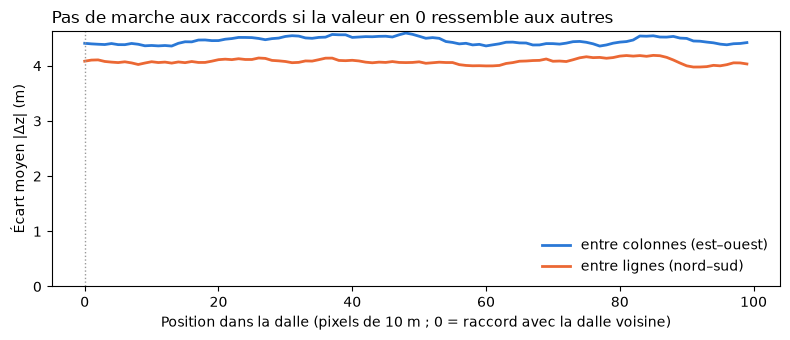

est–ouest : au raccord 4.41 m, ailleurs 4.45 ± 0.06 m
nord–sud : au raccord 4.08 m, ailleurs 4.08 ± 0.05 m


In [4]:
def ecart_selon_position(z, axe):
    """Écart moyen |Δz| entre pixels voisins, selon la position dans la dalle (0 = bord de dalle)."""
    dz = np.abs(np.diff(z, axis=axe))  # dz[i] = écart entre les pixels i et i+1
    moy = np.nanmean(dz, axis=1 - axe)
    position = (np.arange(moy.size) + 1) % 100  # position du pixel i+1 dans sa dalle
    return pd.Series(moy).groupby(position).mean()

est_ouest = ecart_selon_position(mnt, axe=1)
nord_sud = ecart_selon_position(mnt, axe=0)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(est_ouest.index, est_ouest.values, color=BLEU, linewidth=2, label="entre colonnes (est–ouest)")
ax.plot(nord_sud.index, nord_sud.values, color=ORANGE, linewidth=2, label="entre lignes (nord–sud)")
ax.axvline(0, color="#999999", linestyle=":", linewidth=1)
ax.set_xlabel("Position dans la dalle (pixels de 10 m ; 0 = raccord avec la dalle voisine)")
ax.set_ylabel("Écart moyen |Δz| (m)")
ax.set_ylim(0, None)
ax.legend(frameon=False)
ax.set_title("Pas de marche aux raccords si la valeur en 0 ressemble aux autres", loc="left")
fig.tight_layout()
fig.savefig(FIG / "02_verif_raccords_profil.png", dpi=200)
plt.show()

for nom, s in [("est–ouest", est_ouest), ("nord–sud", nord_sud)]:
    print(f"{nom} : au raccord {s[0]:.2f} m, ailleurs {s.drop(0).mean():.2f} ± {s.drop(0).std():.2f} m")

Contrôle visuel des trois croisements : les lignes pointillées marquent les bords de dalles. On ne doit voir aucune ligne droite dans l'ombrage le long de ces pointillés.

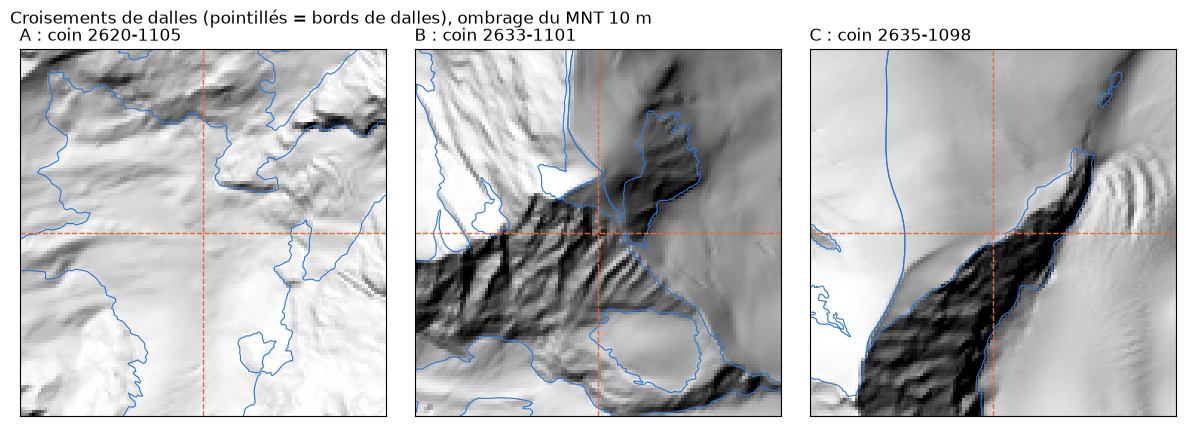

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.3))
for ax, (nom, (x, y)) in zip(axes, croisements.items()):
    fen = from_bounds(x - DEMI, y - DEMI, x + DEMI, y + DEMI, transform)
    lignes, colonnes = fen.toslices()
    ax.imshow(ombre[lignes, colonnes], cmap="gray", vmin=-0.2, vmax=1,
              extent=(x - DEMI, x + DEMI, y - DEMI, y + DEMI))
    glaciers.boundary.plot(ax=ax, color=BLEU, linewidth=0.8)
    ax.axvline(x, color=ORANGE, linestyle="--", linewidth=1)
    ax.axhline(y, color=ORANGE, linestyle="--", linewidth=1)
    ax.set_xlim(x - DEMI, x + DEMI); ax.set_ylim(y - DEMI, y + DEMI)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(""); ax.set_ylabel("")
    ax.set_title(f"{nom} : coin {x // 1000}-{y // 1000}", loc="left")
fig.suptitle("Croisements de dalles (pointillés = bords de dalles), ombrage du MNT 10 m", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIG / "02_verif_raccords_zooms.png", dpi=200)
plt.show()

## 3. Comparaison avec le MNT 2 m d'origine (Alphubel)

Le MNT 10 m doit être une version lissée du 2 m, sans décalage. On compare l'ombrage des deux sur la dalle qui contient les forages d'Alphubel, et on vérifie que chaque pixel de 10 m vaut exactement la moyenne des 5 × 5 pixels de 2 m correspondants.

In [6]:
# Forages glenglat d'Alphubel, convertis en LV95
forages = pd.read_csv(RAW / "glenglat/data/borehole.csv")
forages = forages[forages["glacier_name"].isin(["Alphubel South", "Chessjengletscher"])]
vers_lv95 = Transformer.from_crs(4326, 2056, always_xy=True)
forages["x"], forages["y"] = vers_lv95.transform(forages["longitude"].values, forages["latitude"].values)

alphubel = forages[forages["glacier_name"] == "Alphubel South"]
dalle_x, dalle_y = int(alphubel["x"].mean() // 1000), int(alphubel["y"].mean() // 1000)
fichier_2m = next((RAW / "swissalti3d").glob(f"*_{dalle_x}-{dalle_y}_2_*.tif"))
with rasterio.open(fichier_2m) as src:
    mnt_2m, b = src.read(1), src.bounds
lignes, colonnes = from_bounds(*b, transform).toslices()
mnt_10m_dalle = mnt[lignes, colonnes]

moyenne_5x5 = mnt_2m.reshape(100, 5, 100, 5).mean(axis=(1, 3))
print("Dalle :", fichier_2m.name)
print(f"Écart max entre le MNT 10 m et la moyenne 5x5 du 2 m : {np.abs(mnt_10m_dalle - moyenne_5x5).max():.4f} m")

Dalle : swissalti3d_2024_2633-1100_2_2056_5728.tif
Écart max entre le MNT 10 m et la moyenne 5x5 du 2 m : 0.0000 m


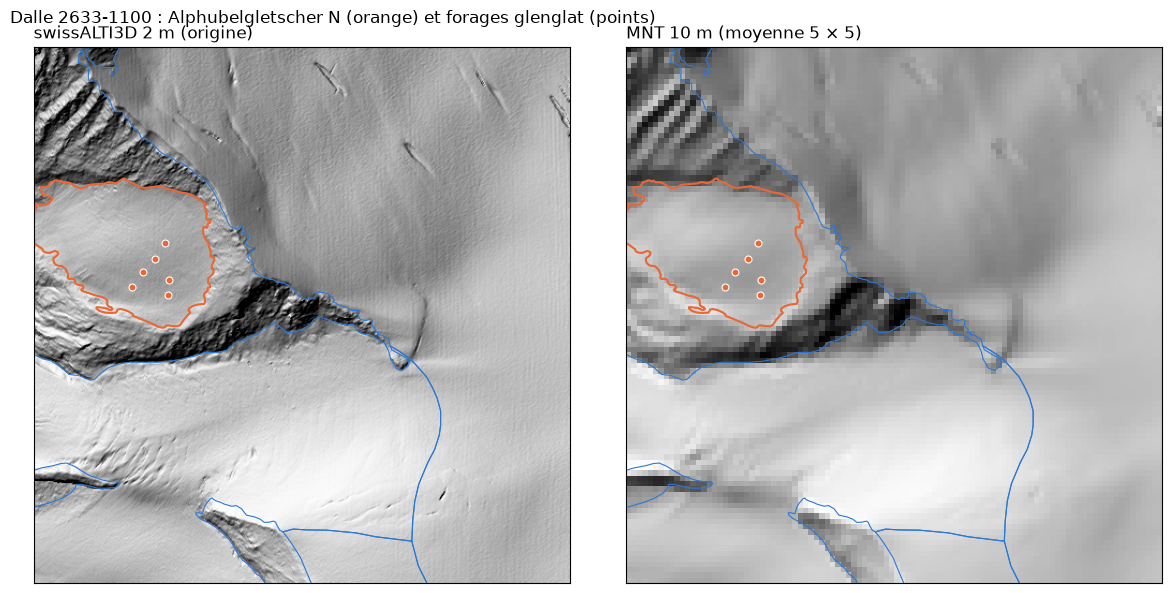

In [7]:
contour_alphubel = glaciers[glaciers["sgi-id"] == "B55-15"]
ext_dalle = (b.left, b.right, b.bottom, b.top)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, z, res, titre in [(axes[0], mnt_2m, 2, "swissALTI3D 2 m (origine)"),
                          (axes[1], mnt_10m_dalle, 10, "MNT 10 m (moyenne 5 × 5)")]:
    ax.imshow(ombrage(z, res), cmap="gray", vmin=-0.2, vmax=1, extent=ext_dalle)
    glaciers.boundary.plot(ax=ax, color=BLEU, linewidth=0.8)
    contour_alphubel.boundary.plot(ax=ax, color=ORANGE, linewidth=1.5)
    ax.scatter(alphubel["x"], alphubel["y"], s=25, color=ORANGE, edgecolor="white", linewidth=0.8, zorder=3)
    ax.set_xlim(b.left, b.right); ax.set_ylim(b.bottom, b.top)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(""); ax.set_ylabel("")
    ax.set_title(titre, loc="left")
fig.suptitle(f"Dalle {dalle_x}-{dalle_y} : Alphubelgletscher N (orange) et forages glenglat (points)",
             x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIG / "02_verif_alphubel_2m_10m.png", dpi=200)
plt.show()

## 4. Altitudes : sommets et forages

**Sommets.** On prend le point le plus haut du MNT dans un rayon de 300 m autour de la position approximative de chaque sommet, à 2 m et à 10 m. Le 10 m doit être un peu plus bas que le 2 m (une moyenne sur 100 m² écrête le sommet) ; le 2 m doit être proche de l'altitude officielle.

Altitudes officielles (cartes swisstopo) et positions approximatives : à confirmer par l'utilisateur.

In [8]:
sommets = pd.DataFrame([
    # nom, lon, lat (approximatifs), altitude officielle (m)
    ("Dom", 7.8592, 46.0940, 4545),
    ("Täschhorn", 7.8569, 46.0839, 4491),
    ("Weisshorn", 7.7163, 46.1014, 4506),
    ("Alphubel", 7.8638, 46.0630, 4206),
    ("Allalinhorn", 7.8950, 46.0464, 4027),
    ("Zinalrothorn", 7.6903, 46.0647, 4221),
], columns=["sommet", "lon", "lat", "officielle"])
sommets["x"], sommets["y"] = vers_lv95.transform(sommets["lon"].values, sommets["lat"].values)


def max_local_2m(x, y, rayon=300):
    """Point le plus haut des dalles 2 m dans un carré de ±rayon autour de (x, y)."""
    haut = -np.inf
    for f in (RAW / "swissalti3d").glob("*_2_*.tif"):
        tx, ty = (int(v) * 1000 for v in f.name.split("_")[2].split("-"))
        if tx + 1000 < x - rayon or tx > x + rayon or ty + 1000 < y - rayon or ty > y + rayon:
            continue  # dalle trop loin
        with rasterio.open(f) as src:
            fen = from_bounds(x - rayon, y - rayon, x + rayon, y + rayon, src.transform)
            z = src.read(1, window=fen, boundless=True, fill_value=-9999)
        haut = max(haut, z.max())
    return haut


def max_local_10m(x, y, rayon=300):
    lignes, colonnes = from_bounds(x - rayon, y - rayon, x + rayon, y + rayon, transform).toslices()
    return np.nanmax(mnt[lignes, colonnes])


sommets["mnt_2m"] = [max_local_2m(x, y) for x, y in zip(sommets["x"], sommets["y"])]
sommets["mnt_10m"] = [max_local_10m(x, y) for x, y in zip(sommets["x"], sommets["y"])]
sommets["2m - officielle"] = sommets["mnt_2m"] - sommets["officielle"]
sommets["10m - 2m"] = sommets["mnt_10m"] - sommets["mnt_2m"]
sommets[["sommet", "officielle", "mnt_2m", "mnt_10m", "2m - officielle", "10m - 2m"]].round(1)

,sommet,officielle,mnt_2m,mnt_10m,2m - officielle,10m - 2m
0,Dom,4545,4545.000000,4542.600098,-0.0,-2.4
1,Täschhorn,4491,4491.299805,4488.700195,0.3,-2.5
2,Weisshorn,4506,4504.799805,4501.899902,-1.2,-2.9
3,Alphubel,4206,4202.600098,4201.299805,-3.4,-1.2
4,Allalinhorn,4027,4027.600098,4024.000000,0.6,-3.6
5,Zinalrothorn,4221,4221.600098,4215.000000,0.6,-6.5


**Forages.** Les altitudes fournies avec les forages glenglat (mesurées sur le terrain en 2024–2025) sont comparées au MNT au même point. Le MNT date de 2024 : quelques mètres d'écart sont attendus (fonte de surface, neige, précision du GNSS des forages, lissage à 10 m).

In [9]:
def altitude_au_point(z, tr, x, y):
    ligne, colonne = rasterio.transform.rowcol(tr, x, y)
    return z[ligne, colonne]


forages["mnt_10m"] = [altitude_au_point(mnt, transform, x, y) for x, y in zip(forages["x"], forages["y"])]
forages["mnt - forage"] = forages["mnt_10m"] - forages["elevation"]
print(f"Écart MNT 10 m - altitude des forages : moyenne {forages['mnt - forage'].mean():+.1f} m, "
      f"max {forages['mnt - forage'].abs().max():.1f} m")
forages[["glacier_name", "label", "date_min", "elevation", "mnt_10m", "mnt - forage"]].round(1)

Écart MNT 10 m - altitude des forages : moyenne +0.1 m, max 2.9 m


,glacier_name,label,date_min,elevation,mnt_10m,mnt - forage
812,Alphubel South,AH1G,2025-08-05,3802.0,3801.300049,-0.7
813,Alphubel South,AH2G,2025-08-06,3759.0,3761.899902,2.9
814,Alphubel South,AH3G,2025-08-06,3820.0,3820.699951,0.7
818,Chessjengletscher,CJ1G,2025-08-07,3031.0,3030.300049,-0.7
819,Chessjengletscher,CJ2G,2025-08-07,3005.0,3003.699951,-1.3
820,Alphubel South,AH1TT,2024-08-21,3775.0,3772.899902,-2.1
821,Alphubel South,AH2TT,2024-08-21,3789.0,3790.699951,1.7
822,Alphubel South,AH3TT,2025-08-06,3781.0,3779.899902,-1.1
823,Chessjengletscher,CJ1TT,2024-08-09,2983.0,2985.600098,2.6
824,Chessjengletscher,CJ2TT,2024-08-09,3027.0,3026.899902,-0.1


## Bilan

| Contrôle | Résultat | Verdict |
|---|---|---|
| Emprise et couverture | 3 400 × 2 300 px de 10 m, 97,1 % couverts ; seuls deux coins au sud sont vides (pas de dalle), loin des glaciers | OK |
| Glaciers retenus | 127 glaciers entiers, aucun coupé par le bord, tous avec une altitude en chaque pixel | OK |
| Raccords entre dalles | Écart entre pixels voisins au raccord identique au reste de la dalle (≈ 4,4 m est–ouest, ≈ 4,1 m nord–sud) ; aucune ligne visible sur les zooms | OK |
| Fidélité au 2 m | Chaque pixel de 10 m est exactement la moyenne 5 × 5 du 2 m (écart 0,0000 m) ; le relief est le même, lissé | OK |
| Sommets | Le 2 m retrouve les altitudes officielles à ±1 m (−3,4 m à l'Alphubel, sommet en dôme de neige) ; le 10 m est 1 à 6,5 m plus bas, effet attendu de la moyenne | OK |
| Forages glenglat | MNT 10 m − altitude des 12 forages : moyenne +0,1 m, max 2,9 m | OK |

Limite à garder en tête : à 10 m, les crêtes et les sommets sont écrêtés de quelques mètres et les ressauts
de moins de 20–30 m de large sont lissés. Pour un profil détaillé d'un petit glacier (Alphubelgletscher N),
revenir au 2 m.